I have an implementation of ngrams somewhere, but i'll just redo it quickly here

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
%%capture
! [ -f names.txt ] || wgetwget https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt

In [24]:
df = pd.read_csv("names.txt", header=None)
names = df[0].str.lower()
df.head()

,0
0,emma
1,olivia
2,ava
3,isabella
4,sophia


In [45]:
alpha = "abcdefghijklmnopqrstuvwxyz."
n = len(alpha)
M = np.zeros((n,n))

In [46]:
char = ord('a')
for name in names:
	k = len(name) - 1
	for cur in range(k):
		i = ord(name[cur]) - char
		j = ord(name[cur+1]) - char
		M[i, j] += 1
	M[k,26] += 1

epsilon = 1e-6
M = M / (epsilon + M.sum(axis=1, keepdims=True))

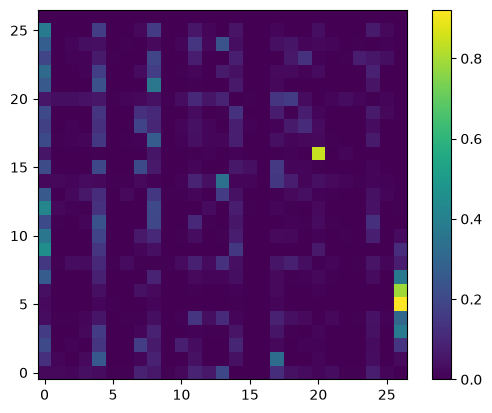

In [47]:
plt.imshow(M, cmap='viridis', origin="lower")
plt.colorbar()
plt.show()

In [ ]:
def gen_name():
	k = np.random.randint(0, 26)

	name = alpha[k]

	i = 0
	while True:
		if i > 50:
			break

		k = np.random.choice(len(M[k]), p=M[k])
		if k == 26:
			break
		name = name + alpha[k]

	return name

gen_name()

'nnnonouttayrakkah'

In [52]:
names = []
for i in range(10):
	names.append(gen_name())
names

['og',
 'bellyrre',
 'vanai',
 'tosai',
 'prakokamid',
 'ponelaynoph',
 'ce',
 'ilorugontaryve',
 'head',
 'onahieye']